# Encontro 11: Testes de hipóteses e comparação de proporções

## 1. Experimentos de títulos no Upworthy

O *Upworthy* realizava testes A/B com diferentes versões de títulos e imagens
para uma mesma notícia. Para cada versão, o arquivo registra quantas vezes ela
foi exibida e quantas dessas exposições resultaram em clique.

Vamos trabalhar com um desses experimentos. As duas versões usam a mesma imagem
e diferem em apenas uma palavra: *creature* e *monkey*.

Como os leitores foram expostos a versões diferentes do título, podemos comparar
as taxas de cliques das duas condições. A primeira pergunta é descritiva:
**qual das duas manchetes recebeu proporcionalmente mais cliques, e qual foi o
tamanho dessa diferença?**

In [ ]:
#| code-fold: true
#| code-summary: "Mostrar importações"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

coin_rng = np.random.default_rng()

permutation_rng = np.random.default_rng(seed=42)
bootstrap_rng = np.random.default_rng(seed=42)

## 2. O teste A/B que vamos analisar

Imagine dois leitores chegando ao *Upworthy*. Um deles vê esta manchete:

> *They spent 4 days in the swamp looking for a creature many thought extinct. On day 5, they found it.*

Outro vê uma versão quase idêntica:

> *They spent 4 days in the swamp looking for a monkey many thought extinct. On day 5, they found it.*

A imagem é a mesma. A notícia é a mesma. Entre os títulos, muda apenas
*creature* por *monkey*.

O *Upworthy* registrou quantas vezes cada versão foi exibida e quantos cliques
cada uma recebeu. Isso nos dá duas proporções para comparar: a taxa de cliques
de *creature* e a taxa de cliques de *monkey*.

## 3. Os dados do Upworthy

O arquivo contém milhares de versões testadas pelo *Upworthy*.

Cada linha representa uma combinação de manchete e imagem usada em um teste.
Duas colunas serão especialmente importantes:

- `impressions`: número de vezes que aquela versão foi exibida;
- `clicks`: número de exposições que terminaram em clique.

Vamos carregar o arquivo e começar olhando sua estrutura.

In [2]:
#| code-fold: true
#| code-summary: "Mostrar leitura dos dados"

upworthy_url = (
    "https://raw.githubusercontent.com/jhlopesalves/eda_humanidades/"
    "refs/heads/main/encontro_11/data/"
    "upworthy-archive-exploratory-packages-03.12.2020.csv"
)

upworthy_df = pd.read_csv(upworthy_url)

In [3]:
upworthy_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 22666 entries, 0 to 22665
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            22666 non-null  int64  
 1   created_at            22666 non-null  str    
 2   updated_at            22666 non-null  str    
 3   clickability_test_id  22666 non-null  str    
 4   excerpt               20249 non-null  str    
 5   headline              22666 non-null  str    
 6   lede                  22654 non-null  str    
 7   slug                  22666 non-null  str    
 8   eyecatcher_id         22644 non-null  str    
 9   impressions           22666 non-null  int64  
 10  clicks                22666 non-null  int64  
 11  significance          22666 non-null  float64
 12  first_place           22666 non-null  bool   
 13  winner                22666 non-null  bool   
 14  share_text            3208 non-null   str    
 15  square                7446 non

Temos uma linha por versão testada e várias informações sobre cada pacote.
Para nossa análise, precisamos localizar o experimento das duas manchetes que
acabamos de conhecer.

O arquivo fornece dois identificadores úteis para isso: um identifica o teste
A/B e outro identifica a imagem utilizada. Como queremos comparar títulos
mantendo a imagem constante, usaremos os dois.

::: {.callout-note collapse="true" title="Fonte dos dados"}
Os dados fazem parte do *Upworthy Research Archive*, descrito por Matias et al.
(2021). O arquivo usado nesta aula corresponde ao subconjunto exploratório
disponibilizado pelo projeto.
:::

Agora precisamos encontrar no arquivo as duas manchetes que acabamos de
conhecer.

As duas contêm uma palavra bastante fácil de procurar: *swamp*. Em vez de
começar com identificadores que ainda não significam nada para nós, podemos
procurar essa palavra diretamente na coluna `headline`.

Isso também nos permitirá verificar se as duas versões realmente pertencem ao
mesmo teste e usaram a mesma imagem.

In [4]:
# Procuramos "swamp" dentro das manchetes do arquivo.
swamp_df = upworthy_df.loc[
    upworthy_df["headline"].str.contains(
        "swamp",
        case=False,
        na=False,
    ),
    [
        "clickability_test_id",
        "eyecatcher_id",
        "headline",
        "impressions",
        "clicks",
    ],
]

# Exibimos as linhas encontradas para conhecer o experimento.
swamp_df

,clickability_test_id,eyecatcher_id,headline,impressions,clicks
760,55413ef4333531000c180000,55412a79643265000ce10200,They spent 4 days in the swamp looking for a c...,2091,32
761,55413ef4333531000c180000,55412a79643265000ce10200,They spent 4 days in the swamp looking for a m...,2014,18


In [5]:
for manchete, imagem in swamp_df[["headline", "eyecatcher_id"]].values:
    print(f"Manchete: {manchete}")
    print(f"Imagem: {imagem}")


Manchete: They spent 4 days in the swamp looking for a creature many thought extinct. On day 5, they found it.
Imagem: 55412a79643265000ce10200
Manchete: They spent 4 days in the swamp looking for a monkey many thought extinct. On day 5, they found it.
Imagem: 55412a79643265000ce10200


In [6]:
# Criamos uma cópia com as colunas que usaremos na análise.
# Assim, podemos adicionar novas colunas sem alterar swamp_df.
experiment_df = swamp_df[
    ["headline", "impressions", "clicks"]
].copy()

experiment_df

,headline,impressions,clicks
760,They spent 4 days in the swamp looking for a c...,2091,32
761,They spent 4 days in the swamp looking for a m...,2014,18


O método `.str.contains()` procura um trecho de texto dentro dos valores de uma
coluna. Aqui, ele procurou `swamp` em cada valor de `headline`.

Encontramos exatamente duas linhas. Além das manchetes, o resultado mostra duas
informações úteis:

- `clickability_test_id` é o identificador do teste A/B;
- `eyecatcher_id` é o identificador da imagem utilizada.

Nas duas linhas, **os dois identificadores são iguais**. Portanto, estamos
comparando duas versões do mesmo teste que usaram a mesma imagem.

## 4. Taxa de cliques por manchete

Para comparar as duas manchetes, precisamos levar em conta quantas vezes cada
uma foi exibida. Usaremos a **taxa de cliques**, ou CTR (*click-through rate*):

$$
\widehat{p}
=
\frac{\text{cliques}}{\text{impressões}}.
$$

Como toda proporção, a CTR varia entre 0 e 1. Podemos multiplicá-la por 100
quando quisermos expressar o resultado como porcentagem.

Vamos calcular essa proporção para as duas manchetes.

In [7]:
# Calculamos a proporção de cliques em relação ao número de impressões.
experiment_df["ctr"] = (
    experiment_df["clicks"]
    / experiment_df["impressions"]
)

# Arredondamos a saída apenas para facilitar a leitura.
experiment_df.round(4)

,headline,impressions,clicks,ctr
760,They spent 4 days in the swamp looking for a c...,2091,32,0.0153
761,They spent 4 days in the swamp looking for a m...,2014,18,0.0089


A versão com *creature* apresentou a maior taxa de cliques.

Na escala de porcentagem, as duas CTRs correspondem a aproximadamente 1,53% e
0,89%. A diferença parece visível, mas ainda precisamos quantificá-la.

In [8]:
# Damos nomes curtos às duas condições.
experiment_df.index = [
    "creature",
    "monkey",
]

# Calculamos a diferença observada entre as duas CTRs.
observed_difference = (
    experiment_df.loc["creature", "ctr"]
    - experiment_df.loc["monkey", "ctr"]
)

100 * observed_difference

np.float64(0.6366244514130404)

* **Hipótese alternativa `($H_1$)`:** Representa o efeito, a diferença sistemática ou a associação que estamos investigando (as probabilidades de clique são diferentes).
* **Hipótese nula `($H_0$)`:** Representa o complemento lógico — o cenário de ausência de efeito, no qual qualquer flutuação observada se deve puramente ao acaso (as probabilidades de clique são idênticas).

Formalmente, para as condições *creature* e *monkey*, escrevemos:

$$H_0: p_{\text{creature}} = p_{\text{monkey}}$$

$$H_1: p_{\text{creature}} \neq p_{\text{monkey}}$$


## 5. Hipóteses e inferência

### 5.1. O erro que o Python não lança: descrição vs. inferência

Até aqui, usamos bastante Python e já aplicamos várias ferramentas estatísticas. Python, nesse percurso, tem operado exatamente como uma **ferramenta formal**: uma linguagem com regras sintáticas e semânticas explícitas. Se tentarmos acessar uma variável que ainda não foi definida, ou se passarmos um argumento incompatível com o que uma função exige, o interpretador interrompe a execução imediatamente. Quem já programou por algum tempo conhece bem esse muro:

```text
NameError
TypeError
ValueError
```

Quando isso acontece, o programa para e nos avisa sem rodeios: *alguma coisa naquilo que você tentou fazer viola as regras do sistema*.

Em pesquisa empírica, porém, o buraco é bem mais embaixo. Você pode escrever um código sintaticamente impecável, rodar um teste estatístico sem nenhum aviso de erro, obter um número matematicamente válido com oito casas decimais e, ainda assim, chegar a uma conclusão que os seus dados **absolutamente não sustentam**. O Python — ou o R, ou qualquer pacote estatístico — é obediente demais para o nosso próprio bem; ele nunca vai interromper o seu script com um *traceback* dizendo:

```text
GeneralizationError: estes dados não permitem concluir isso sobre toda a população.

```

Essa exceção não existe no interpretador. Nós é que precisamos instalá-la no nosso próprio raciocínio metodológico.

Nas ciências humanas e na linguística, costumamos dividir o trabalho entre métodos qualitativos, quantitativos ou mistos. Mas o ponto crucial aqui não é a velha dicotomia entre "poucos casos analisados em profundidade" versus "muitos casos transformados em números". A distinção que realmente importa neste momento é entre **descrição** e **inferência**:

* **O nível descritivo/exploratório:** Uma análise qualitativa pode investigar práticas discursivas ou contextos específicos sem nenhuma pretensão de generalizar uma taxa para fora dali. Da mesma forma, uma análise quantitativa pode ser *puramente descritiva*. Se avaliarmos todas as redações de uma turma e encontrarmos determinada construção sintática em 37% delas, podemos afirmar com total segurança: *"nesta coleção de textos, a construção ocorre em 37% dos casos"*. Zero problema até aqui; estamos apenas resumindo o que de fato medimos.
* **O salto inferencial:** O cenário muda radicalmente no instante em que damos um passo além e dizemos: *"portanto, aproximadamente 37% dos estudantes brasileiros utilizam essa construção"*. Aqui, deixamos de descrever a nossa amostra e passamos a fazer uma **inferência** — isto é, usamos um conjunto finito de observações para fazer uma afirmação sobre um processo gerador, uma população ou um fenômeno mais amplo que não observamos diretamente.

É exatamente nesse salto que o pesquisador precisa parar de olhar apenas para o código e começar a fazer perguntas metodológicas incômodas: *(a)* Como esses dados foram coletados e qual foi o mecanismo de amostragem/atribuição? *(b)* Quem tinha chance real de entrar na amostra e quem foi sistematicamente excluído? *(c)* A nossa variável operacional realmente mede o fenômeno teórico sobre o qual queremos falar? *(d)* Se repetíssemos o estudo amanhã sob as mesmas condições, observaríamos um padrão semelhante, ou essa diferença surgiu apenas por flutuação aleatória?

E sejamos diretos sobre uma ilusão muito comum na nossa área: **ter "muitos dados" não resolve essas questões automaticamente**. Um corpus com dez milhões de palavras pode fornecer uma descrição milimétrica *daquelas dez milhões de palavras*, mas isso não significa, por si só, que ele represente todos os falantes, todos os registros ou "a língua portuguesa". Do mesmo modo, avaliar cinco mil alunos de uma única escola privada não transforma essa escola em uma miniatura dos estudantes de um país inteiro. Tamanho de amostra ($N$) e representatividade/dispersão são dimensões ortogonais: uma amostra gigantesca, porém enviesada, só nos dá uma estimativa extremamente precisa do nosso próprio viés.

### 5.2. O compromisso com o mundo: $H_0$, $H_1$ e o problema da variabilidade

Para evitar que a nossa transição dos dados para a conclusão seja guiada apenas por intuição ou desejo (*wishful thinking*), precisamos formalizar **hipóteses**. Uma hipótese científica útil não pode ser uma frase elástica, compatível com qualquer resultado imaginável; ela precisa assumir um compromisso empírico com o mundo, de modo que determinados resultados possam contradizê-la.

Compare estas duas formulações sobre o nosso experimento de manchetes:

1. *"A escolha da manchete **pode ou não** alterar a probabilidade de clique."*
2. *"A escolha da manchete **altera** a probabilidade de clique."*

A primeira afirmação é empiricamente vazia: se encontrarmos uma diferença enorme, ela está "certa"; se encontrarmos exatamente a mesma taxa, ela continua "certa". Uma frase que explica tudo não explica nada. A segunda afirmação, por outro lado, arrisca o pescoço: ela prevê que as duas condições não são equivalentes no processo que gera os cliques.

Na inferência estatística clássica, organizamos esse compromisso dividindo o espaço de possibilidades em duas hipóteses mutuamente exclusivas e exaustivas:

* **Hipótese alternativa ($H_1$):** Representa o efeito, a diferença sistemática ou a associação que estamos investigando (as probabilidades de clique são diferentes).
* **Hipótese nula ($H_0$):** Representa o complemento lógico — o cenário de ausência de efeito, no qual qualquer flutuação observada se deve puramente ao acaso (as probabilidades de clique são idênticas).

Formalmente, para as condições *creature* e *monkey*, escrevemos:

$$H_0: p_{\text{creature}} = p_{\text{monkey}}$$

$$H_1: p_{\text{creature}} \neq p_{\text{monkey}}$$

Preste muita atenção à notação aqui, porque ela separa dois níveis da realidade que jamais devem ser confundidos:

| Notação | Nível | O que representa na prática |
| --- | --- | --- |
| $\widehat{p}_{\text{creature}}$ e $\widehat{p}_{\text{monkey}}$ | **Amostral (Observado)** | As proporções empíricas que já calculamos diretamente na nossa tabela de dados (o "chapéu" em $\widehat{p}$ indica uma estimativa calculada a partir de dados finitos). |
| $p_{\text{creature}}$ e $p_{\text{monkey}}$ | **Populacional (Processo Gerador)** | As probabilidades reais — porém diretamente invisíveis — do processo subjacente que gerou os cliques, sobre o qual queremos fazer inferência. |

Agora, você pode estar pensando: *"Ok, mas se a hipótese nula afirma que $p_{\text{creature}} = p_{\text{monkey}}$, e nós acabamos de calcular no Python que $\widehat{p}_{\text{creature}} \neq \widehat{p}_{\text{monkey}}$, qual problema resta? Nós já não refutamos $H_0$?"*

**Não.** E entender por que a resposta é "não" é entender o coração da estatística.

Mesmo quando dois processos possuem *exatamente* a mesma probabilidade subjacente ($p_1 = p_2$), amostras finitas quase nunca produzem proporções idênticas ($\widehat{p}_1 = \widehat{p}_2$). Se você entregar duas moedas perfeitamente honestas ($p = 0{,}50$) para dois alunos e pedir que cada um faça 100 lançamentos, um pode obter 47 caras ($\widehat{p}_1 = 0{,}47$) e o outro 54 caras ($\widehat{p}_2 = 0{,}54$). Observar $0{,}47 \neq 0{,}54$ na amostra não prova que as moedas têm propriedades físicas diferentes; prova apenas que **existe variabilidade amostral**. O nosso trabalho não é constatar que os números na tela são diferentes — para isso bastaria um operador `!=` no Python —, mas sim quantificar se essa diferença é grande demais para ser explicada apenas pelo acaso.

### 5.3. Testes unilaterais vs. bilaterais (ou: por que não mudar as regras depois do jogo)

Antes de avançarmos para o cálculo, há uma decisão metodológica importante na formulação de $H_1$.

Se tivéssemos uma teoria prévia muito forte — estabelecida *antes* da coleta e da inspeção dos dados — que previsse especificamente uma vantagem para a palavra *creature*, poderíamos ter formulado uma **hipótese direcional (unilateral)**: a probabilidade de clique em *creature* é estritamente maior do que em *monkey*.

Mas não foi essa a pergunta que motivou o estudo. A nossa questão original era aberta: *trocar uma palavra pela outra altera a probabilidade de clique?* Tanto um aumento quanto uma queda nos cliques seriam resultados relevantes para a nossa análise. Por isso, adotamos uma **hipótese bilateral**:

$$H_1: p_{\text{creature}} \neq p_{\text{monkey}}$$

Embora a direção que observamos nos dados continue sendo fundamental para interpretarmos o fenômeno, vale uma regra de ouro de higiene metodológica: **você não pode espiar os números primeiro, ver qual condição ganhou, e só então decidir que "só aquela direção contava"**. Escolher uma hipótese unilateral *depois* de conhecer o resultado é trapacear com o espaço de probabilidades, inflando artificialmente a chance de encontrar um efeito onde ele não existe.

### 5.4. Construindo um modelo de referência: rumo à permutação

Voltemos, então, ao número que o Python nos entregou. Calculamos uma diferença empírica de $0{,}64$ ponto percentual entre as taxas de clique das duas manchetes. O código rodou em milissegundos, sem `TypeError` e sem `ValueError`. Agora começa o verdadeiro trabalho inferencial.

Em vez de encararmos esse $0{,}64$ ponto percentual no vácuo e tentarmos adivinhar no olhômetro se ele é "grande" ou "pequeno", vamos submetê-lo a duas perguntas diagnósticas:

> 1. **Se a hipótese nula ($H_0$) fosse verdadeira** — isto é, se a palavra na manchete fosse totalmente irrelevante e ambas tivessem exatamente a mesma probabilidade de clique —, que tipo de diferenças entre as taxas esperaríamos observar **apenas por sorteio/acaso**?
> 2. **Onde a diferença que realmente observamos ($0{,}64$ ponto percentual) se situa** dentro dessa distribuição de diferenças geradas pelo puro acaso?
>
>

Responder à primeira pergunta nos dará um **modelo de referência** (uma distribuição nula). Responder à segunda nos dirá se o nosso resultado é perfeitamente banal sob $H_0$ ou se ele é comum nesse modelo de referência ou se ocupa uma região extrema da distribuição nula.

E para simular esse mundo onde $H_0$ é verdadeira usando apenas os dados que já temos em mãos, precisaremos de uma operação computacional simples e poderosa: **permutação**.



#### Um experimento com uma moeda justa

Na lógica do teste, as duas hipóteses não recebem o mesmo tratamento.
$H_0$ ocupa a posição de referência, e o ônus da evidência recai sobre
$H_1$: não interpretamos uma diferença amostral como evidência de uma
diferença sistemática apenas porque ela apareceu nos dados.

Para rejeitar $H_0$, exigiremos que o resultado observado seja suficientemente
difícil de compatibilizar com aquilo que o próprio modelo nulo consegue
produzir, segundo uma regra de decisão definida antes de conhecermos o
resultado. Esse compromisso importa: não podemos tornar a regra mais permissiva
depois apenas porque o resultado obtido favorece a hipótese que gostaríamos de
defender.

In [9]:
# Criamos uma lista vazia para guardar os lançamentos.
coin_flips = []

In [10]:
# Sorteamos um único lançamento:
# 1 representa cara e 0 representa coroa.
flip = coin_rng.integers(
    low=0,
    high=2,
)

# Guardamos o novo resultado junto aos lançamentos anteriores.
coin_flips.append(flip)

# Traduzimos 0 e 1 para facilitar a leitura em sala.
result = (
    "cara"
    if flip == 1
    else "coroa"
)

print(
    f"Lançamento {len(coin_flips)}: {result}"
)

display(
    [
        "cara" if moeda == 1 else "coroa"
        for moeda in coin_flips
    ]
)

Lançamento 1: coroa


['coroa']

In [11]:
# A média de 0s e 1s é a proporção de caras observada até agora.
sample_proportion = np.mean(
    coin_flips
)

print(
    f"Lançamento {len(coin_flips)}: {result}"
)

print(
    f"Proporção de caras: {sample_proportion:.3f}"
)

Lançamento 1: coroa
Proporção de caras: 0.000


In [12]:
# Simulamos uma amostra maior da mesma moeda justa.
large_sample = coin_rng.integers(
    low=0,
    high=2,
    size=100,
)

# Calculamos a proporção de caras na nova amostra.
large_sample.mean()

np.float64(0.52)

## 6. Teste de permutação

Já observamos uma diferença de aproximadamente $0{,}64$ ponto percentual entre
as CTRs das duas manchetes.

Agora a hipótese nula precisa enfrentar essa diferença.

Nossa referência é:

$$
H_0:
p_{\text{creature}}
=
p_{\text{monkey}}.
$$

Sob esse modelo, nenhuma das duas condições possui uma vantagem sistemática na
probabilidade de clique. Isso não significa que as CTRs observadas precisariam
ser idênticas: como vimos no experimento da moeda, resultados amostrais podem
variar mesmo quando o processo subjacente permanece o mesmo.

O que precisamos descobrir, portanto, é:

> **que diferenças entre as CTRs o próprio modelo nulo consegue produzir?**

Para responder a essa pergunta, usaremos um **teste de permutação**.

### 6.1. O que será permutado?

Nosso experimento contém:

- 2.091 impressões na condição *creature*, com 32 cliques;
- 2.014 impressões na condição *monkey*, com 18 cliques.

No total, temos:

$$
2.091 + 2.014 = 4.105
$$

impressões, das quais:

$$
32 + 18 = 50
$$

resultaram em clique.

Podemos representar cada impressão como um resultado binário:

- `1` para clique;
- `0` para ausência de clique.

Assim, nossos dados contêm exatamente 50 valores `1` e 4.055 valores `0`.

No teste de permutação, **esses resultados não são alterados**. Continuamos
tendo os mesmos 50 cliques, os mesmos 4.055 não cliques e os mesmos tamanhos de
grupo.

O que muda é a associação entre os resultados e as duas condições.

Sob $H_0$, redistribuímos os resultados entre um grupo com 2.091 observações e
outro com 2.014 observações, sem dar vantagem sistemática a nenhuma das duas
manchetes.

### 6.2. Uma permutação

Imagine que uma dessas redistribuições colocasse 27 dos 50 cliques no grupo
*creature* e os 23 restantes no grupo *monkey*.

Teríamos então:

$$
\widehat p_{\text{creature}}^{*}
=
\frac{27}{2091}
$$

e

$$
\widehat p_{\text{monkey}}^{*}
=
\frac{23}{2014}.
$$

Calculamos novamente nossa estatística:

$$
T^{*}
=
\widehat p_{\text{creature}}^{*}
-
\widehat p_{\text{monkey}}^{*}.
$$

Essa é **uma diferença possível sob o procedimento nulo**.

Em outra permutação, os 50 cliques seriam distribuídos de outra maneira e
obteríamos outro valor de $T^{*}$.

### 6.3. Procedimento para permutacao

O procedimento completo é:

1. mantemos os resultados observados e os tamanhos dos grupos;
2. redistribuímos os resultados entre as duas condições;
3. calculamos novamente a diferença entre as CTRs;
4. guardamos essa diferença;
5. repetimos o processo milhares de vezes.

Depois de 10.000 permutações teremos:

$$
T_1^{*},
T_2^{*},
T_3^{*},
\ldots,
T_{10000}^{*}.
$$

Esses 10.000 valores formarão nossa **distribuição nula**: uma referência que
mostra quais diferenças nossa estatística pode produzir quando usamos $H_0$
como modelo.

Só depois compararemos com ela a diferença realmente observada:

$$
T_{\text{obs}}
\approx
0{,}64
\text{ ponto percentual}.
$$

O SciPy realizará as redistribuições para nós. Antes disso, precisamos preparar
os resultados das duas condições e definir formalmente a estatística que será
recalculada em cada permutação.

In [13]:
# Convertemos cliques e impressões em resultados binários.
def click_outcomes(clicks, impressions):
    # Tudo que não resultou em clique será representado por 0.
    non_clicks = impressions - clicks

    # Criamos um valor 1 para cada clique e um valor 0
    # para cada impressão que não resultou em clique.
    return np.repeat(
        [1, 0],
        [clicks, non_clicks],
    )

In [14]:
# Preparamos os resultados da condição creature.
creature_outcomes = click_outcomes(
    clicks=experiment_df.loc["creature", "clicks"],
    impressions=experiment_df.loc["creature", "impressions"],
)

# Preparamos os resultados da condição monkey.
monkey_outcomes = click_outcomes(
    clicks=experiment_df.loc["monkey", "clicks"],
    impressions=experiment_df.loc["monkey", "impressions"],
)

# A média dos valores binários recupera exatamente a CTR de cada grupo.
creature_outcomes.mean(), monkey_outcomes.mean()

(np.float64(0.015303682448589193), np.float64(0.00893743793445879))

Como 1 representa clique e 0 representa ausência de clique, a média desses
vetores recupera exatamente a CTR de cada condição.

Isso significa que já temos os dois grupos na forma necessária para o teste.
O próximo passo é dizer ao SciPy **qual estatística** ele deve recalcular a
cada redistribuição. No nosso caso, essa estatística é a diferença entre
as duas CTRs.

Agora precisamos informar ao SciPy qual quantidade deve ser recalculada em cada
permutação.

Nossa estatística continua sendo a mesma que usamos desde o início: a diferença
entre as duas taxas de cliques.

In [15]:
# Calculamos a diferença entre as CTRs das duas condições.
def ctr_difference(creature, monkey):
    return (
        creature.mean()
        - monkey.mean()
    )

In [16]:
# Executamos o teste de permutação com o SciPy.
permutation_result = stats.permutation_test(
    # Estes são os dois grupos que queremos comparar.
    data=(
        creature_outcomes,
        monkey_outcomes,
    ),

    # Em cada permutação, recalculamos a diferença entre as CTRs.
    statistic=ctr_difference,

    # As duas condições são grupos independentes.
    permutation_type="independent",

    # Diferenças nas duas direções são relevantes para nossa hipótese.
    alternative="two-sided",

    # Usamos 10.000 redistribuições para aproximar a referência nula.
    n_resamples=10_000,

    # Mantemos o teste reproduzível independentemente do experimento da moeda.
    rng=permutation_rng,
)

Agora vamos dizer ao SciPy quais são os dois grupos, qual estatística ele deve recalcular, que a hipótese é bilateral e quantas permutações queremos executar.

## 7. Distribuição nula

O SciPy não produziu apenas um valor final. Durante o teste, ele recalculou nossa
diferença entre CTRs em cada permutação.

Essas diferenças formam a **distribuição nula**: os valores da nossa estatística
produzidos pelo procedimento quando usamos $H_0$ como referência.

In [17]:
# Recuperamos as diferenças calculadas durante as permutações.
null_differences = (
    permutation_result.null_distribution
)


# Organizamos as diferenças produzidas pelas permutações em um DataFrame.
null_df = pd.DataFrame(
    {
        "permutacao": np.arange(
            1,
            len(null_differences) + 1,
        ),
        "diferenca_pp": 100 * null_differences,
    }
)

# Observamos algumas das diferenças produzidas sob H0.
null_df.head(10)

,permutacao,diferenca_pp
0,1,-0.240664
1,2,-0.143187
2,3,-0.143187
3,4,-0.143187
4,5,-0.045711
5,6,-0.240664
6,7,0.831577
7,8,0.051766
8,9,-0.338140
9,10,0.441672


In [18]:
# Resumimos a distribuição das diferenças produzidas sob H0.
null_df["diferenca_pp"].describe()

count    10000.000000
mean        -0.004030
std          0.346501
min         -1.507857
25%         -0.240664
50%         -0.045711
75%          0.246719
max          1.221483
Name: diferenca_pp, dtype: float64

In [19]:
# Recuperamos a diferença realmente observada no experimento.
observed_pp = 100 * observed_difference

print(
    f"Diferença observada: {observed_pp:.2f} p.p."
)

print(
    f"Média das diferenças sob H0: "
    f"{null_df['diferenca_pp'].mean():.5f} p.p."
)

Diferença observada: 0.64 p.p.
Média das diferenças sob H0: -0.00403 p.p.


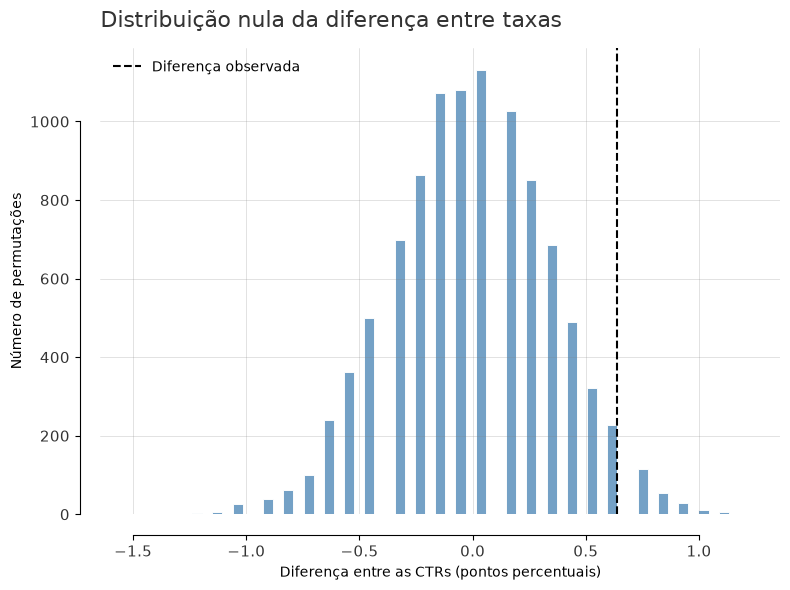

In [20]:
#| label: fig-upworthy-nula
#| fig-cap: "Distribuição nula da diferença entre as taxas de cliques."
#| fig-alt: "Histograma das diferenças obtidas em 10.000 permutações. A distribuição se concentra perto de zero e uma linha tracejada indica a diferença observada."
#| code-fold: true
#| code-summary: "Mostrar construção do gráfico"

fig, ax = plt.subplots(
    figsize=(8, 6)
)

sns.histplot(
    data=null_df,
    x="diferenca_pp",
    bins="fd",
    color="steelblue",
    edgecolor="white",
    ax=ax,
)

# Marcamos a diferença observada.
ax.axvline(
    observed_pp,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Diferença observada",
)

ax.set_title(
    "Distribuição nula da diferença entre taxas",
    loc="left",
    fontsize=16,
    color="#333333",
    pad=15,
)

ax.set(
    xlabel="Diferença entre as CTRs (pontos percentuais)",
    ylabel="Número de permutações",
)

ax.legend(
    frameon=False
)

ax.tick_params(
    axis="both",
    labelsize=11,
    labelcolor="#333333",
)

ax.grid(
    alpha=0.4,
    linewidth=0.4,
    color="grey",
)

sns.despine(
    ax=ax,
    top=True,
    trim=True,
    offset=15,
)

fig.tight_layout()
plt.show()

A distribuição se concentra perto de zero.

Isso faz sentido: sob $H_0$, nenhuma das duas condições possui uma vantagem
sistemática. Ainda assim, as redistribuições produzem diferenças em ambas as
direções.

Por isso, $H_0$ não prevê que toda diferença observada seja exatamente zero.
Ele produz uma distribuição de diferenças possíveis em torno de zero.

A linha tracejada mostra a diferença realmente observada no experimento.

Agora temos aquilo que não tínhamos quando calculamos apenas os $0{,}64$ ponto
percentual: uma **referência** para avaliar essa diferença.

A próxima pergunta é:

> **quão extremo é o resultado observado em relação à distribuição nula?**

O valor-p resume justamente essa comparação.

## 8. Regra de decisão e valor-p

Construímos uma distribuição nula e já sabemos qual pergunta queremos fazer:

> **quão extremo é o resultado observado em relação à referência construída sob
> $H_0$?**

Antes de consultar o valor-p calculado pelo teste, porém, precisamos separar
duas coisas:

- o **valor-p** será produzido pelos dados e pelo procedimento estatístico;
- o **nível de significância**, representado por $\alpha$, é uma regra de
  decisão escolhida pelo pesquisador.

### 8.1. Definindo $\alpha$

O nível de significância estabelece quão dispostos estamos a rejeitar $H_0$
quando usamos uma regra binária de decisão.

Em termos de erro tipo I:

$$
P(
\text{rejeitar } H_0
\mid
H_0 \text{ verdadeira}
)
\approx
\alpha,
$$

para um procedimento corretamente calibrado.

Valores como $0{,}05$, $0{,}01$ e $0{,}10$ não são constantes naturais.
Representam diferentes níveis de tolerância ao erro tipo I.

Um valor menor de $\alpha$ torna a regra mais exigente para rejeitar $H_0$;
um valor maior torna a regra mais permissiva. Em uma pesquisa substantiva, essa
escolha deve considerar o desenho do estudo, as consequências dos diferentes
tipos de erro e o objetivo confirmatório ou exploratório da análise.

O valor $0{,}05$ tornou-se uma convenção extremamente comum, mas continua sendo
uma **convenção**, não uma fronteira científica universal.

Este notebook é uma análise didática e retrospectiva; portanto, não vamos
fingir que houve uma pré-especificação que não ocorreu. Ainda assim, para
representar corretamente a lógica do teste, adotaremos agora:

$$
\alpha = 0{,}05,
$$

**antes de consultar o valor-p**, e manteremos essa regra independentemente do
resultado que aparecer.

In [21]:
# Definimos a regra de decisão antes de consultar o valor-p.
alpha = 0.05

alpha

0.05

### 8.2. O valor-p

O **valor-p** quantifica quão extremo é o resultado observado em relação à
distribuição de referência construída sob $H_0$, segundo a regra do teste.

Em termos gerais, ele responde à pergunta:

> **Se $H_0$ fosse o nosso modelo de referência, qual seria a probabilidade de
> obter um resultado considerado pelo teste pelo menos tão extremo quanto o
> observado?**

A expressão **"tão ou mais extremo"** depende da hipótese alternativa e da regra
adotada pelo teste.

No nosso caso:

$$
H_1:
p_{\text{creature}}
\neq
p_{\text{monkey}},
$$

portanto diferenças nas duas direções são relevantes.

Com `alternative="two-sided"`, o `scipy.stats.permutation_test()` calcula as
probabilidades nas duas direções e retorna duas vezes a menor delas.

Agora podemos finalmente consultar o valor-p produzido pelo teste.

In [22]:
# Recuperamos o valor-p bilateral calculado pelo teste de permutação.
permutation_p_value = permutation_result.pvalue

permutation_p_value

np.float64(0.0887911208879112)

### 8.1. Interpretando o resultado

Para este experimento, obtemos:

$$
p \approx 0{,}089.
$$

Esse valor deve ser lido em relação à referência nula que acabamos de construir.

Nosso resultado está relativamente afastado do centro da distribuição nula:
diferenças consideradas tão ou mais extremas pela regra bilateral do teste não
são as mais comuns sob $H_0$.

Ao mesmo tempo, um valor-p próximo de $0{,}089$ não coloca nosso resultado em
uma região extraordinariamente rara dessa referência.

De maneira geral, quanto menor o valor-p, mais extremo é o resultado observado
em relação ao comportamento esperado da estatística sob $H_0$.

O valor-p descreve, portanto, **evidência em relação ao modelo nulo**. Ele não
descreve o tamanho da diferença: essa informação continua sendo dada pela
diferença observada de aproximadamente $0{,}64$ ponto percentual.

In [23]:
# Recuperamos o valor-p bilateral calculado pelo teste de permutação.
permutation_p_value = permutation_result.pvalue

print(
    f"Valor-p: {permutation_p_value:.3f}"
)

# Aplicamos a regra de decisão definida anteriormente.
if permutation_p_value <= alpha:
    print("Rejeitamos H0.")
else:
    print("Não rejeitamos H0.")

Valor-p: 0.089
Não rejeitamos H0.


### 8.3. Interpretando o resultado

Obtivemos:

$$
p \approx 0{,}089.
$$

Esse valor deve ser interpretado em relação à distribuição nula que construímos.

O resultado observado está relativamente afastado do centro dessa referência:
ele não é um resultado particularmente comum sob $H_0$. Ao mesmo tempo, também
não ocupa uma região extraordinariamente rara.

Nossa regra de decisão havia sido definida como:

$$
\alpha = 0{,}05.
$$

Como:

$$
0{,}089 > 0{,}05,
$$

**não rejeitamos $H_0$**.

Essa decisão deve ser respeitada. Não podemos observar $p=0{,}089$ e, somente
então, trocar o limiar para $0{,}10$ porque esse novo valor produziria uma
conclusão diferente.

Ao mesmo tempo, $0{,}05$ não transforma dois resultados como $p=0{,}049$ e
$p=0{,}051$ em fenômenos científicos radicalmente diferentes. O valor-p
continua sendo uma quantidade contínua; $\alpha$ é a regra adicional que
transforma essa evidência em uma decisão binária.

Não rejeitar $H_0$ também não demonstra que ela seja verdadeira. Significa que
o resultado não atingiu o critério que estabelecemos para rejeitá-la.

### 8.4. Limites da interpretação

O valor-p é calculado condicionando o raciocínio ao modelo nulo:

$$
P(
\text{resultado extremo segundo a regra do teste}
\mid
H_0
).
$$

Partimos de $H_0$ e perguntamos como a estatística se comportaria sob essa
referência.

Isso é diferente de:

$$
P(
H_0
\mid
\text{resultado}
),
$$

que seria a probabilidade de $H_0$ dado aquilo que observamos.

Portanto, $p \approx 0{,}089$ não significa que exista 8,9% de probabilidade de
$H_0$ ser verdadeira. Também não significa que exista 91,1% de probabilidade de
$H_1$ ser verdadeira ou 8,9% de probabilidade de o resultado ter acontecido
"por acaso".

O valor-p responde a uma pergunta mais específica: **como nosso resultado se
comporta em relação à distribuição produzida pelo procedimento sob $H_0$?**

E mesmo um valor-p muito pequeno não corrige um desenho inadequado, uma unidade
de análise errada, uma medida ruim ou uma generalização que os dados não
sustentam.

O `GeneralizationError` continua sendo responsabilidade do pesquisador.

O teste de hipótese termina aqui.

Temos uma diferença observada de aproximadamente $0{,}64$ ponto percentual e um
teste bilateral por permutação com:

$$
p \approx 0{,}089.
$$

Com $\alpha=0{,}05$, não rejeitamos $H_0$.

Mas existe uma pergunta que o valor-p **não tentou responder**:

> **qual é o tamanho do efeito observado, e qual medida de tamanho de efeito
> faz sentido para este tipo de dado?**

Essa pergunta nos leva a uma discussão diferente.

## 9. Tamanho de efeito: uma medida serve para qualquer problema?

O valor-p não mede a magnitude do efeito.

Uma resposta muito comum para a pergunta "qual é o tamanho do efeito?" é
calcular **Cohen's $d$**, a diferença entre duas médias padronizada por um
desvio-padrão:

$$
d
=
\frac{
\bar{x}_1-\bar{x}_2
}{
s_{\text{pooled}}
}.
$$

Essa medida é extremamente conhecida e pode ser útil para variáveis contínuas
em contextos nos quais uma diferença expressa em unidades de desvio-padrão seja
interpretável.

Nosso resultado, porém, é **binário**:

- `1` = clique;
- `0` = ausência de clique.

A média de cada grupo é, portanto, sua própria proporção de cliques.

Isso significa que podemos calcular Cohen's $d$ mecanicamente para nossos
vetores de 0 e 1.

Vamos fazer isso — e depois perguntar se o número obtido realmente melhora nossa
compreensão do efeito.

In [24]:
# Calculamos Cohen's d com o desvio-padrão combinado dos dois grupos.
def cohens_d(first_group, second_group):
    pooled_sd = np.sqrt(
        (
            first_group.var(ddof=1)
            + second_group.var(ddof=1)
        )
        / 2
    )

    return (
        first_group.mean()
        - second_group.mean()
    ) / pooled_sd


cohens_d_value = cohens_d(
    creature_outcomes,
    monkey_outcomes,
)

cohens_d_value

np.float64(0.058190016735382495)

In [ ]:
# Mantemos exatamente a mesma diferença observada entre as duas condições.
# Assim, em todos os cenários abaixo, creature continuará 0,64 p.p.
# acima de monkey. A única coisa que vamos mudar será a taxa de base.
same_difference = observed_difference

# Testamos a mesma diferença absoluta em três níveis de referência: perto de 1%, 10% e 40%.
for p_monkey in [0.01, 0.10, 0.40]:
    # Construímos a probabilidade de creature mantendo a diferença fixa.
    p_creature = p_monkey + same_difference

    # Para uma variável binária, a variância é p * (1 - p).
    #
    # Calculamos a variância de cada grupo e fazemos a média das duas,
    # seguindo a forma de Cohen's d que usa os dois desvios com o mesmo peso.
    pooled_sd = np.sqrt(
        (
            p_creature * (1 - p_creature)
            + p_monkey * (1 - p_monkey)
        )
        / 2
    )

    # Cohen's d divide a diferença entre as médias
    # pelo desvio-padrão combinado.
    #
    # Como a diferença permanece fixa, qualquer mudança em d
    # será causada pela mudança na dispersão.
    d = same_difference / pooled_sd

    # Mostramos, lado a lado:
    # - a taxa de base;
    # - a mesma diferença absoluta;
    # - o Cohen's d produzido em cada cenário.
    print(
        f"Baseline: {100 * p_monkey:>5.1f}% "
        f"| diferença: {100 * same_difference:.2f} p.p. "
        f"| Cohen's d: {d:.3f}"
    )

Baseline:   1.0% | diferença: 0.64 p.p. | Cohen's d: 0.056
Baseline:  10.0% | diferença: 0.64 p.p. | Cohen's d: 0.021
Baseline:  40.0% | diferença: 0.64 p.p. | Cohen's d: 0.013


### 9.1. O que Cohen's $d$ está fazendo?

Cohen's $d$ padroniza a diferença entre duas médias:

$$
d
=
\frac{
\bar{x}_1 - \bar{x}_2
}{
s_{\text{pooled}}
}.
$$

Portanto, ele não mede apenas a diferença entre os grupos. Ele mede essa
diferença **em unidades de desvio-padrão**.

Para variáveis binárias, isso cria um problema importante de interpretação. A
variância depende diretamente da própria probabilidade:

$$
\operatorname{Var}(Y)
=
p(1-p).
$$

Logo, quando mudamos a taxa de base, mudamos também o desvio-padrão usado no
denominador de Cohen's $d$.

Foi exatamente o que vimos no experimento anterior: mantivemos a diferença
absoluta fixa em $0{,}64$ ponto percentual, mas Cohen's $d$ mudou conforme a
taxa de base mudou.

Isso mostra que Cohen's $d$ não é uma medida universal de magnitude. Ele
expressa magnitude em uma escala específica: **desvios-padrão**.

Para este problema, essa escala é pouco informativa. Nosso resultado é binário,
a taxa de cliques é muito baixa e a diferença entre as probabilidades possui uma
interpretação direta em pontos percentuais.

### Cliff's delta

Cliff's delta é uma medida não paramétrica de tamanho de efeito baseada em
**probabilidades de dominância** entre dois grupos.

Sua definição é:

$$
\delta
=
P(X_1 > X_2)
-
P(X_1 < X_2).
$$

A interpretação é direta:

- $\delta = 1$: valores do primeiro grupo são sempre maiores;
- $\delta = -1$: valores do segundo grupo são sempre maiores;
- $\delta = 0$: não há dominância líquida entre os grupos.

Portanto:

$$
-1 \leq \delta \leq 1.
$$

Cliff's delta não padroniza a diferença por um desvio-padrão. Ele mede quanto
um grupo tende a produzir valores maiores do que o outro.



### 9.2. Uma alternativa não paramétrica: Cliff's delta

Cliff's delta mede a diferença entre duas probabilidades de dominância:

$$
\delta
=
P(X_{\text{creature}} > X_{\text{monkey}})
-
P(X_{\text{creature}} < X_{\text{monkey}}).
$$

Ele não divide a diferença por um desvio-padrão.

No nosso caso, os únicos valores possíveis são 0 e 1. Portanto:

$$
P(X_{\text{creature}} > X_{\text{monkey}})
=
p_{\text{creature}}
(1-p_{\text{monkey}})
$$

e

$$
P(X_{\text{creature}} < X_{\text{monkey}})
=
(1-p_{\text{creature}})
p_{\text{monkey}}.
$$

Subtraindo:

$$
\delta
=
p_{\text{creature}}
-
p_{\text{monkey}}.
$$

Portanto, para este resultado binário:

$$
\boxed{
\delta
=
p_{\text{creature}}
-
p_{\text{monkey}}
}
$$

Cliff's delta coincide exatamente com a diferença entre as proporções.

No nosso experimento:

$$
\delta
\approx
0{,}0064,
$$

ou:

$$
0{,}64
\text{ ponto percentual}.
$$

A diferença entre as CTRs já era, portanto, uma medida diretamente
interpretável de tamanho de efeito.

Agora resta uma pergunta:

> **quão incerta é essa estimativa de tamanho de efeito?**

Para responder, voltamos ao bootstrap.

In [ ]:
# Para resultados binários, Cliff's delta coincide com a diferença entre as duas proporções.
cliffs_delta_value = ctr_difference(
    creature_outcomes,
    monkey_outcomes,
)

# Reamostramos cada condição separadamente para estimar a incerteza dessa medida de tamanho de efeito.
effect_bootstrap_result = stats.bootstrap(
    data=(
        creature_outcomes,
        monkey_outcomes,
    ),

    # Neste caso binário, esta estatística também é Cliff's delta.
    statistic=ctr_difference,

    # As observações pertencem a grupos independentes.
    paired=False,

    # Geramos 10.000 reamostragens com reposição.
    n_resamples=10_000,

    # Construímos um intervalo de confiança de 95%.
    confidence_level=0.95,

    # Usamos os percentis da distribuição bootstrap.
    method="percentile",

    # Mantemos esta etapa reproduzível e independente da permutação.
    rng=bootstrap_rng,
)

# Recuperamos os limites do intervalo.
effect_ci_low = (
    effect_bootstrap_result.confidence_interval.low
)
effect_ci_high = (
    effect_bootstrap_result.confidence_interval.high
)

print(
    f"Cliff's delta: "
    f"{cliffs_delta_value:.4f}"
)

print(
    f"Diferença equivalente: "
    f"{100 * cliffs_delta_value:.2f} p.p."
)

print(
    f"IC bootstrap de 95%: "
    f"[{effect_ci_low:.4f}, {effect_ci_high:.4f}]"
)

print(
    f"IC bootstrap em pontos percentuais: "
    f"[{100 * effect_ci_low:.2f}, "
    f"{100 * effect_ci_high:.2f}  ] p.p."
)

Cliff's delta: 0.0064
Diferença equivalente: 0.64 p.p.
IC bootstrap de 95%: [-0.0004, 0.0131]
IC bootstrap em pontos percentuais: [-0.04, 1.31  ] p.p.


### 9.3. Magnitude e incerteza

Agora temos uma resposta muito mais completa para a pergunta sobre magnitude.

Cohen's $d$ produziu aproximadamente:

$$
d \approx 0{,}058,
$$

mas vimos que essa padronização depende da taxa de base porque, em uma variável
binária, a própria variância depende de $p$.

Cliff's delta, por outro lado, simplifica neste problema para:

$$
\widehat{\delta}
=
\widehat p_{\text{creature}}
-
\widehat p_{\text{monkey}}
\approx
0{,}0064,
$$

ou:

$$
0{,}64
\text{ ponto percentual}.
$$

O bootstrap coloca incerteza em torno dessa medida. O intervalo de 95% fica
aproximadamente entre:

$$
-0{,}04
\quad\text{e}\quad
1{,}31
\text{ ponto percentual}.
$$

Esse intervalo inclui zero e também diferenças positivas maiores do que a
estimativa pontual.

Isso não altera nosso valor-p e não "corrige" o teste de hipótese. São
informações diferentes:

- o teste de permutação avaliou o resultado em relação a $H_0$;
- a medida de efeito descreveu a magnitude observada;
- o bootstrap descreveu a incerteza dessa magnitude.

O ponto metodológico é mais importante do que escolher uma medida famosa:
**tamanho de efeito precisa fazer sentido para a variável e para a pergunta
científica.**

## 10. Aplicações em linguística e Humanidades

A lógica que usamos não depende especificamente de manchetes ou taxas de
cliques. O que muda de uma pesquisa para outra são as unidades de análise,
as variáveis e o desenho que justifica a inferência.

**Em linguística de corpus**, poderíamos comparar uma medida entre grupos de
textos, falantes ou documentos. Nesse caso, é fundamental identificar a
verdadeira unidade de análise: milhões de palavras em um corpus não significam
necessariamente milhões de observações independentes. Se a pergunta compara
grupos de textos, por exemplo, são os textos — e não cada token isoladamente —
que podem constituir as unidades relevantes para a inferência.

**Em estudos de comunicação**, um experimento com diferentes formulações de uma
pergunta, mensagem ou enquadramento pode seguir uma lógica muito próxima à do
Upworthy: condições diferentes, uma variável de resposta e uma comparação entre
os resultados observados.

**Em estudos literários**, poderíamos comparar uma medida estilística entre
obras, capítulos, períodos ou grupos previamente definidos. Novamente, o teste
adequado depende de como essas unidades foram selecionadas e de quais
observações podem ser tratadas como independentes.

O procedimento estatístico pode mudar de um problema para outro. A lógica
inferencial permanece: definir a pergunta, identificar as unidades de análise,
formular um modelo de referência, quantificar a evidência e respeitar os
limites do desenho.

## 11. Escopo da inferência

O desenho A/B permite uma comparação causal entre as condições dentro do
experimento, desde que a atribuição aleatória tenha funcionado como planejado.

No caso principal, as duas versões compartilham a mesma imagem e diferem na
formulação da manchete. Podemos, portanto, comparar essas duas condições no
contexto específico em que foram testadas.

Isso não estabelece uma regra geral como:

> usar *creature* em vez de *monkey* aumenta a taxa de cliques.

Essa afirmação ultrapassaria os dados. Ela se refere implicitamente a outras
notícias, outros textos, outros públicos e outros contextos que não participaram
deste experimento.

Uma hipótese linguística geral exigiria vários itens e contextos, além de um
desenho que permitisse generalizar sobre essa variação.

Também precisamos respeitar aquilo que as variáveis realmente medem.
`impressions` registra quantas vezes o pacote foi exibido e `clicks` quantas
dessas exposições resultaram em clique.

Um clique não mede diretamente compreensão, concordância, persuasão ou interesse
duradouro.

A inferência precisa respeitar tanto **como os dados foram produzidos** quanto
**aquilo que as variáveis representam**.

::: {.callout-note collapse="true" title="Modelo de relato"}

A versão com *creature* recebeu 32 cliques em 2.091 impressões, correspondendo
a uma CTR de 1,53%; a versão com *monkey* recebeu 18 cliques em 2.014
impressões, com CTR de 0,89%.

A diferença observada, *creature* menos *monkey*, foi de aproximadamente
0,64 ponto percentual. O teste bilateral por permutação produziu:

$$
p \approx 0{,}089.
$$

Com o nível de significância adotado nesta análise,

$$
\alpha = 0{,}05,
$$

não rejeitamos $H_0$.

Como medida de magnitude, Cliff's delta foi aproximadamente $0{,}0064$. Para
este resultado binário, essa medida coincide exatamente com a diferença de
proporções, isto é, aproximadamente 0,64 ponto percentual.

O intervalo bootstrap de 95% para essa medida ficou aproximadamente entre
−0,04 e 1,31 ponto percentual.

Os dados observados favorecem a versão com *creature*, mas a incerteza ainda é
compatível com diferenças muito pequenas e com uma pequena diferença na direção
oposta.

A conclusão se restringe às duas versões avaliadas no contexto específico deste
experimento e não estabelece um efeito geral das palavras *creature* e *monkey*
sobre taxas de cliques.

:::

## 12. Síntese

Começamos com uma pergunta descritiva: qual das duas manchetes apresentou maior
taxa de cliques e qual foi a diferença observada?

Encontramos aproximadamente:

$$
\widehat p_{\text{creature}}
-
\widehat p_{\text{monkey}}
=
0{,}64
\text{ ponto percentual}.
$$

A partir daí, o problema tornou-se inferencial.

A hipótese nula forneceu um modelo de referência. Com o teste de permutação,
redistribuímos os resultados entre as condições, recalculamos repetidamente a
mesma estatística e construímos uma distribuição nula.

Antes de consultar o valor-p, definimos uma regra de decisão:

$$
\alpha = 0{,}05.
$$

O teste bilateral produziu:

$$
p \approx 0{,}089,
$$

portanto não rejeitamos $H_0$ segundo essa regra.

Isso encerrou a pergunta do teste de hipótese, mas não a análise da magnitude.

Em seguida, examinamos o que significa escolher uma medida de tamanho de efeito.
Cohen's $d$ pôde ser calculado mecanicamente para os dados binários, mas vimos
que sua padronização depende da própria taxa de base.

Cliff's delta ofereceu uma interpretação não paramétrica e revelou uma
propriedade importante deste caso: para resultados binários, ele coincide
exatamente com a diferença entre as proporções.

Por fim, usamos bootstrap para quantificar a incerteza dessa medida de efeito.

Ao final, temos três informações distintas:

- **magnitude:** aproximadamente 0,64 ponto percentual;
- **evidência em relação a $H_0$:** $p \approx 0{,}089$;
- **incerteza da magnitude:** IC bootstrap de 95% de aproximadamente
  $[-0{,}04,\ 1{,}31]$ ponto percentual.

Nenhuma delas funciona isoladamente como um veredito científico.

Também aprendemos que escolher uma técnica conhecida não basta. A estatística
precisa fazer sentido para a variável, para o desenho e para a pergunta de
pesquisa.

O Python consegue lançar `NameError`, `TypeError` e `ValueError`.

Ele não lança automaticamente um erro quando escolhemos uma medida inadequada,
alteramos uma regra depois de olhar o resultado ou generalizamos além daquilo
que os dados sustentam.

O `GeneralizationError` continua sendo responsabilidade do pesquisador.